# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()


,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()


,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
print("\nInformación del dataset plans:")
plans.info()


Información del dataset plans:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
print("\nInformación del dataset users:")
users.info()


Información del dataset users:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
print("\nInformación del dataset usage:")
usage.info()


Información del dataset usage:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print("Cantidad de valores nulos en users:")
print(users.isna().sum())

# Proporción de valores nulos para users
print("Proporción de valores nulos en users:")
print(users.isna().mean())

Cantidad de valores nulos en users:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
Proporción de valores nulos en users:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# Cantidad de valores nulos para usage
print("\nCantidad de valores nulos en usage:")
print(usage.isna().sum())

# Proporción de valores nulos para usage
print("\nProporción de valores nulos en usage:")
print(usage.isna().mean())


Cantidad de valores nulos en usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos en usage:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?


## **Diagnóstico de valores nulos**

- **users – city:** Presenta un 11,73 % de valores nulos; recomiendo investigar los registros faltantes y conservarlos si no es posible recuperar la ciudad de forma confiable.

- **users – churn_date:** Tiene un 88,35 % de valores nulos; probablemente corresponden a usuarios que no han cancelado el servicio, por lo que no deben imputarse sin verificar su significado.

- **usage – date:** Presenta un 0,13 % de valores nulos; recomiendo revisar esos registros y evaluar su eliminación únicamente si no es posible recuperar la fecha y esta es necesaria para el análisis.

- **usage – duration:** Tiene un 55,19 % de valores nulos; es necesario comprobar si corresponden a registros que no son llamadas antes de decidir cómo tratarlos.

- **usage – length:** Presenta un 44,74 % de valores nulos; se debe verificar si la ausencia depende del tipo de consumo registrado antes de imputar o eliminar datos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# Explorar columnas numéricas de users
print("Resumen estadístico de las columnas numéricas de users:")
print(users[['user_id', 'age']].describe())

Resumen estadístico de las columnas numéricas de users:
            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- **La columna user_id:** Los identificadores van de 10000 a 13999 y no presentan valores fuera del rango observado que indiquen anomalías.

- **La columna age:** Presenta un valor mínimo de -999, que es una edad inválida y probablemente un sentinel. Se debe investigar y tratar como dato faltante antes del análisis.

In [13]:
# Explorar columnas numéricas de usage
print("Resumen estadístico de las columnas numéricas de usage:")
print(usage[['id', 'user_id', 'duration', 'length']].describe())

Resumen estadístico de las columnas numéricas de usage:
                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- **Las columnas id y user_id:** Los identificadores presentan rangos coherentes con los registros de los datasets; no se observan valores negativos ni anomalías evidentes en el resumen estadístico.

- **Las columnas duration y length:** Se observan valores máximos de 120 y 1490, respectivamente, superiores a sus medianas de 3,5 y 50. También hay valores de cero; se recomienda revisar estos registros para determinar si son válidos o representan anomalías.

In [14]:
# Explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for columna in columnas_user:
    print(f"\nValores únicos de {columna}:")
    print(users[columna].value_counts(dropna=False))


Valores únicos de city:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores únicos de plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64


- **La columna city:** Presenta 96 registros con el símbolo ? y 469 valores nulos. El símbolo ? parece representar información faltante o desconocida, por lo que se recomienda investigarlo y unificar su tratamiento con los valores ausentes.

- **La columna plan:** Solo contiene las categorías Basico y Premium, sin valores inesperados ni categorías adicionales. No se identifican anomalías en esta columna.

In [15]:
# Explorar la columna categórica de usage
print("Valores únicos de type:")
print(usage['type'].value_counts(dropna=False))

print("\nCategorías únicas:")
print(usage['type'].unique())

Valores únicos de type:
text    22092
call    17908
Name: type, dtype: int64

Categorías únicas:
['call' 'text']


- **La columna type:** Presenta únicamente las categorías call y text, que corresponden a llamadas y mensajes. No se identifican valores categóricos inesperados.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías? 


## Diagnóstico de valores inválidos o sentinels

Se identificó un valor inválido de -999 en la columna age y 96 registros con el símbolo ? en la columna city, que podrían representar datos faltantes. Se recomienda investigar ambos casos y tratar los valores confirmados como inválidos antes del análisis. En duration y length se observan valores extremos y ceros que deben revisarse para determinar si son válidos. Las columnas user_id, id, plan y type no presentan anomalías evidentes en las exploraciones realizadas.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(
    users['reg_date'], errors='coerce'
)

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(
    usage['date'], errors='coerce'
)

In [18]:
# Revisar los años presentes en `reg_date` de users
print("Cantidad de registros por año en reg_date:")
users['reg_date'].dt.year.value_counts().sort_index()

Cantidad de registros por año en reg_date:


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

- **En `reg_date`:** Se observan registros de los años 2022 (1.314), 2023 (1.316), 2024 (1.330) y 2026 (40). El año 2026 está fuera del rango establecido, ya que los datos llegan hasta 2024; se recomienda revisar y corregir esas fechas si es posible verificar los valores originales.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64

- **En `date`:** Los 39.950 registros con fecha válida corresponden al año 2024. No se observan otros años en esta columna; sin embargo, existen 50 fechas ausentes que deben tenerse en cuenta durante el análisis.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

## **Diagnóstico de fechas fuera de rango**

En reg_date se identificaron 40 registros del año 2026, posteriores al límite establecido de 2024. Se recomienda verificar y corregir las fechas con información confiable; si no es posible validarlas, deben tratarse como inválidas. En date, las fechas válidas corresponden a 2024 y no se identificaron años posteriores al límite; los 50 valores ausentes deben revisarse antes del análisis.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [22]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].isna().sum()

40

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().mean())

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().mean())

type
call    0.99933
text    0.00000
Name: length, dtype: float64

## **Diagnóstico de nulos en duration y length**

- **Duration:** Presenta prácticamente un 100 % de valores nulos en los registros de tipo text y ningún valor nulo en call. Esto indica que la ausencia depende del tipo de registro; recomiendo conservar los nulos sin imputarlos, ya que la duración corresponde a las llamadas.

- **length:** Presenta aproximadamente un 100 % de valores nulos en los registros de tipo call y ningún valor nulo en text. Esto indica que la ausencia depende del tipo de registro; recomiendo conservar los nulos sin imputarlos, ya que la longitud corresponde a los mensajes.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)  # conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int)  # conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# Observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile[[
    "age",
    "cant_mensajes",
    "cant_llamadas",
    "cant_minutos_llamada"
]].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
(user_profile["plan"].value_counts(normalize=True) * 100).round(2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

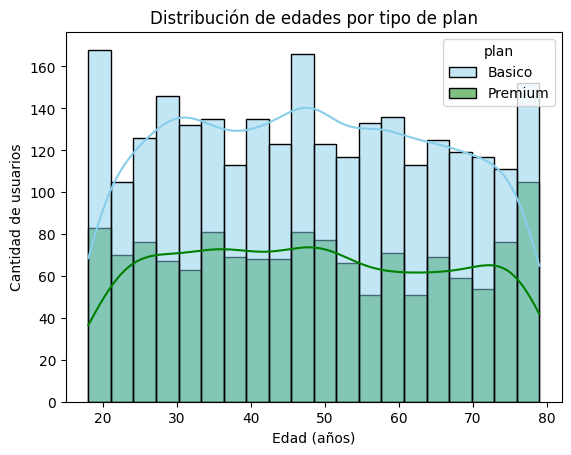

In [30]:
# Histograma para visualizar la edad (age)
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    data=user_profile,
    x="age",
    hue="plan",
    hue_order=["Basico", "Premium"],
    palette=["skyblue", "green"],
    bins=20,
    kde=True
)

plt.title("Distribución de edades por tipo de plan")
plt.xlabel("Edad (años)")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
- La distribución de edades es aproximadamente simétrica en ambos planes, con una asimetría cercana a cero (0,04 en Básico y 0,07 en Premium).

- La edad promedio es muy similar: 48,04 años en Básico y 48,31 en Premium. No se observan diferencias relevantes en la edad de los usuarios según el plan.

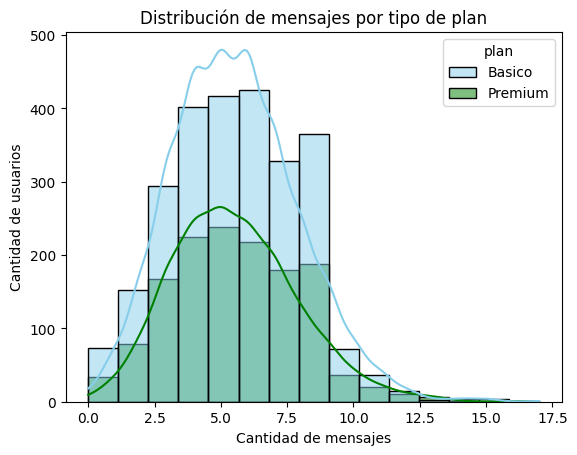

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(
    data=user_profile,
    x="cant_mensajes",
    hue="plan",
    hue_order=["Basico", "Premium"],
    palette=["skyblue", "green"],
    bins=15,
    kde=True
)

plt.title("Distribución de mensajes por tipo de plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
- Ambos planes presentan un promedio prácticamente idéntico de mensajes: 5,53 en Básico y 5,52 en Premium, con una mediana de 5 en ambos casos.

- Las distribuciones presentan una asimetría positiva moderada (0,44 en Básico y 0,49 en Premium), lo que indica un sesgo hacia la derecha.

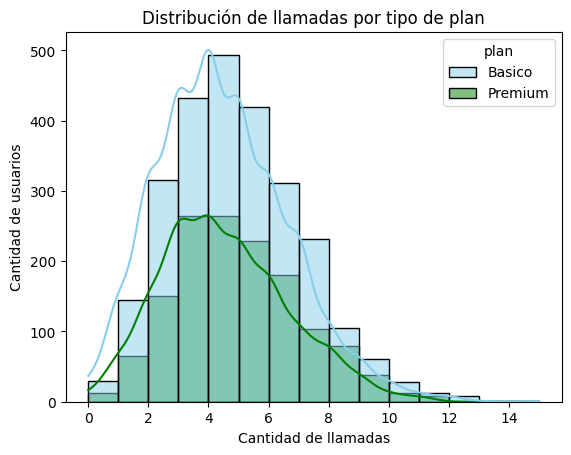

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile,
    x="cant_llamadas",
    hue="plan",
    hue_order=["Basico", "Premium"],
    palette=["skyblue", "green"],
    bins=15,
    kde=True
)

plt.title("Distribución de llamadas por tipo de plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
-  La cantidad promedio de llamadas es similar entre los planes: 4,46 en Básico y 4,52 en Premium, con una mediana de 4 llamadas en ambos grupos.

- Las distribuciones presentan un sesgo moderado hacia la derecha, más marcado en Básico (0,54) que en Premium (0,45).

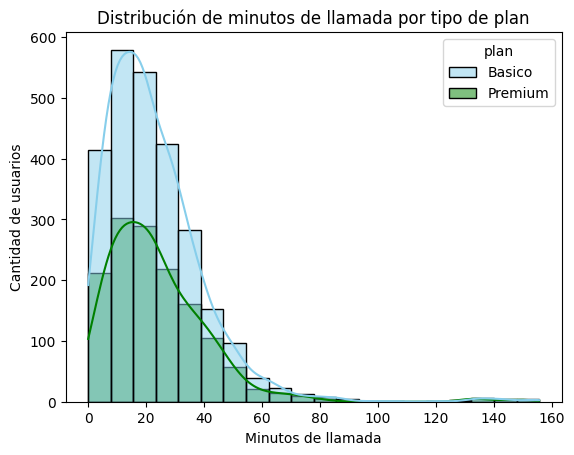

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile,
    x="cant_minutos_llamada",
    hue="plan",
    hue_order=["Basico", "Premium"],
    palette=["skyblue", "green"],
    bins=20,
    kde=True
)

plt.title("Distribución de minutos de llamada por tipo de plan")
plt.xlabel("Minutos de llamada")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
- Los usuarios Premium registran un promedio ligeramente mayor de minutos de llamada (24,08) que los usuarios Básico (22,91). Las medianas también muestran esta diferencia: 20,64 y 19,54 minutos, respectivamente.

- Ambas distribuciones presentan una fuerte asimetría positiva (2,62 en Premium y 2,45 en Básico), lo que indica una cola hacia la derecha y la presencia de usuarios con consumos considerablemente elevados.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>
- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

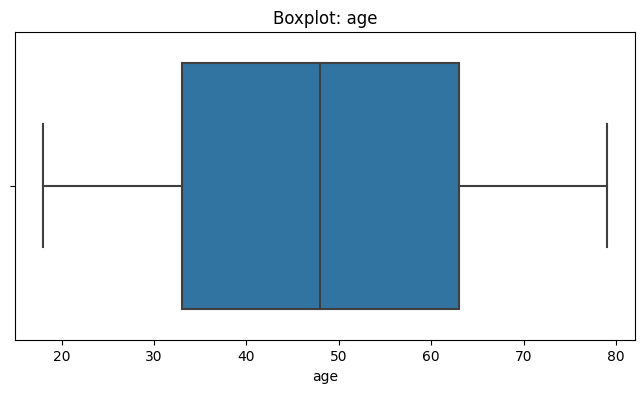

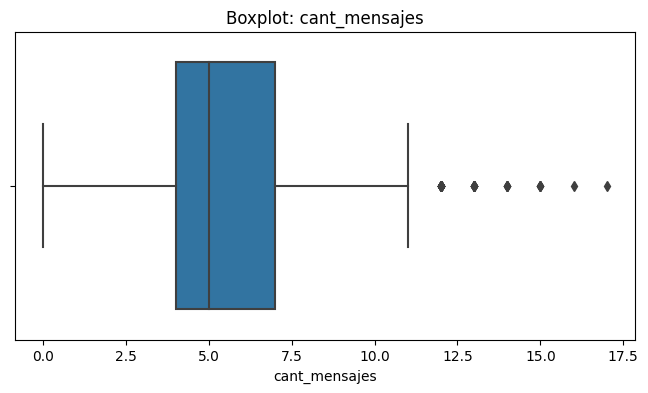

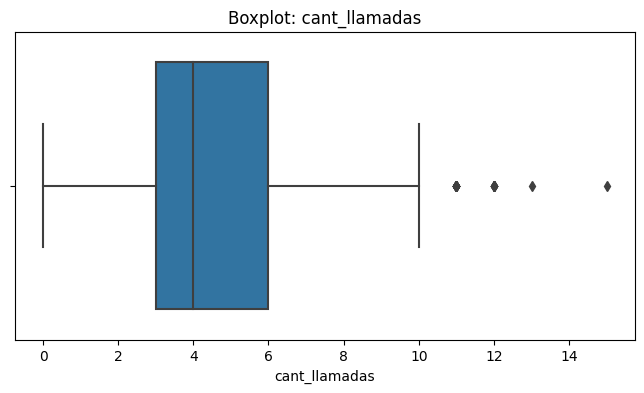

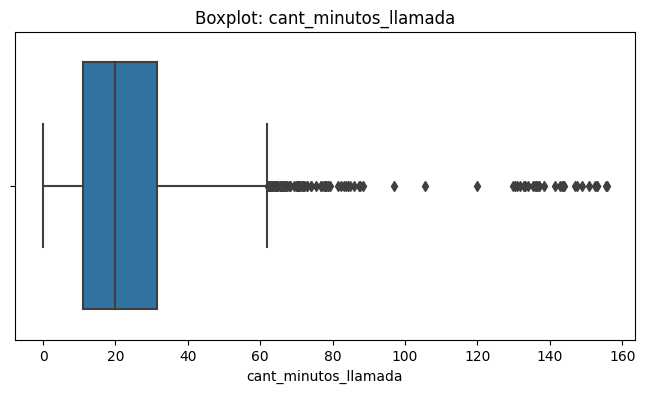

In [34]:
# Visualizando usando BoxPlot 
import matplotlib.pyplot as plt
import seaborn as sns

columnas_numericas = [
    "age",
    "cant_mensajes",
    "cant_llamadas",
    "cant_minutos_llamada"
]

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col)
    plt.title(f"Boxplot: {col}")
    plt.xlabel(col)
    plt.show()

💡Insights: 
- **Age:** No se observan outliers evidentes. Los valores se distribuyen aproximadamente entre 18 y 80 años y no aparecen puntos aislados fuera de los bigotes.
- **cant_mensajes:** Se observan varios puntos aislados en el extremo superior, aproximadamente desde 12 hasta 17 mensajes. Son posibles valores atípicos superiores.
- **cant_llamadas:** Se observan algunos puntos aislados por encima del bigote superior, aproximadamente entre 11 y 15 llamadas.
- **cant_minutos_llamada:** Presenta numerosos puntos aislados en el extremo superior, incluidos valores que se aproximan a 160 minutos. La distribución tiene una cola superior extensa.

In [36]:
# Calcular límites con el método IQR
columnas_limites = [
    "cant_mensajes",
    "cant_llamadas",
    "cant_minutos_llamada"
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_superior = Q3 + 1.5 * IQR

    outliers = user_profile[user_profile[col] > limite_superior]

    print(f"\nVariable: {col}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Límite superior: {limite_superior:.2f}")
    print(f"Valor máximo: {user_profile[col].max():.2f}")
    print(f"Cantidad de outliers: {len(outliers)}")


Variable: cant_mensajes
Q1: 4.00
Q3: 7.00
IQR: 3.00
Límite superior: 11.50
Valor máximo: 17.00
Cantidad de outliers: 46

Variable: cant_llamadas
Q1: 3.00
Q3: 6.00
IQR: 3.00
Límite superior: 10.50
Valor máximo: 15.00
Cantidad de outliers: 30

Variable: cant_minutos_llamada
Q1: 11.12
Q3: 31.41
IQR: 20.30
Límite superior: 61.86
Valor máximo: 155.69
Cantidad de outliers: 109


In [37]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 

- **cant_mensajes:** presenta posibles outliers superiores, ya que el máximo de 17 supera el límite IQR de 11,5. Se recomienda conservarlos provisionalmente si corresponden a actividad real.

- **cant_llamadas:** presenta posibles outliers superiores, pues el máximo de 15 supera el límite IQR de 10,5. Estos valores deben mantenerse si no representan errores de registro.

- **cant_minutos_llamada:** presenta posibles outliers superiores, dado que el máximo de 155,69 minutos supera el límite IQR de 61,86. Debido a la alta variabilidad, conviene revisarlos antes de decidir si se mantienen.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [38]:
# Crear columna grupo_uso
user_profile["grupo_uso"] = "Alto uso"

user_profile.loc[
    (user_profile["cant_llamadas"] < 5) &
    (user_profile["cant_mensajes"] < 5),
    "grupo_uso"
] = "Bajo uso"

user_profile.loc[
    (user_profile["cant_llamadas"] < 10) &
    (user_profile["cant_mensajes"] < 10) &
    (user_profile["grupo_uso"] != "Bajo uso"),
    "grupo_uso"
] = "Uso medio"

# Verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad

user_profile["grupo_edad"] = "Adulto Mayor"

user_profile.loc[
    user_profile["age"] < 60,
    "grupo_edad"
] = "Adulto"

user_profile.loc[
    user_profile["age"] < 30,
    "grupo_edad"
] = "Joven"

# Verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

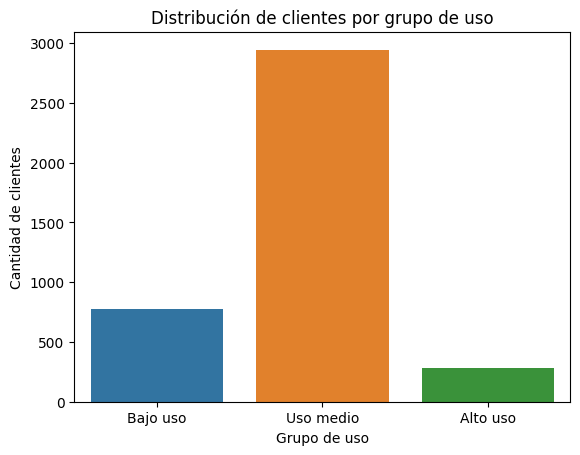

In [41]:
# Visualización de los segmentos por uso
sns.countplot(
    data=user_profile,
    x="grupo_uso",
    order=["Bajo uso", "Uso medio", "Alto uso"]
)

plt.title("Distribución de clientes por grupo de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de clientes")
plt.show()

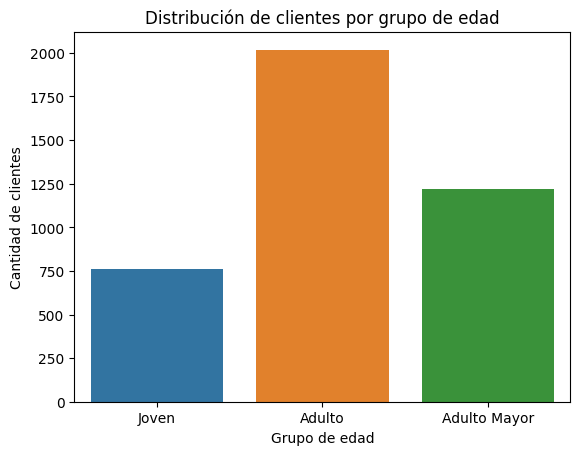

In [42]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile,
    x="grupo_edad",
    order=["Joven", "Adulto", "Adulto Mayor"]
)

plt.title("Distribución de clientes por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de clientes")
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**


## **Análisis ejecutivo – ConnectaTel**

**Problemas detectados en los datos**

Durante la exploración y limpieza se identificaron valores inválidos, datos faltantes y fechas fuera del periodo de referencia. Los principales hallazgos fueron:

- **Edad (`age`):** se encontraron 55 registros con el valor inválido `-999`, equivalentes al **1,38 % de los 4.000 usuarios**. Este valor se reemplazó por la mediana para evitar que distorsionara el análisis.
- **Ciudad (`city`):** se identificaron 469 valores nulos (**11,73 %**) y 96 registros con el símbolo `?` (**2,40 %**). En conjunto, son 565 registros (**14,13 %**) con la ciudad faltante o desconocida. Este porcentaje representa información incompleta, no 565 errores confirmados.
- **Fecha de registro (`reg_date`):** se encontraron 40 fechas de 2026 (**1,00 % de los usuarios**), fuera del periodo de referencia que llega hasta 2024. Se marcaron como nulas para evitar utilizarlas como fechas válidas.
- **Fecha de uso (`date`):** se detectaron 50 valores nulos entre 40.000 registros (**0,13 %**), que deben considerarse en los análisis que dependan de la fecha.
- **Duración (`duration`) y longitud (`length`):** se encontraron 22.076 y 17.896 valores nulos, respectivamente. Estos faltantes se relacionan con el tipo de registro: la duración corresponde a las llamadas y la longitud a los mensajes. Por ello, no se imputaron valores sin justificación.
- **Fecha de cancelación (`churn_date`):** se identificaron 3.534 valores nulos (**88,35 % de los usuarios**). Estos pueden corresponder a clientes que no han cancelado el servicio, por lo que no se consideran automáticamente errores.

La limpieza permitió tratar los valores inválidos identificados y evitar que los datos faltantes se interpretaran incorrectamente. Los registros que requerían una validación adicional se deben analizar según su naturaleza antes de utilizarlos para tomar decisiones comerciales.

**Segmentos por edad**

De los 4.000 clientes analizados, la distribución por edad fue la siguiente:

- **Adultos:** 2.018 clientes (**50,45 %**).
- **Adultos mayores:** 1.222 clientes (**30,55 %**).
- **Jóvenes:** 760 clientes (**19,00 %**).

Los adultos representan aproximadamente la mitad de la base y constituyen el grupo más numeroso. Los adultos mayores representan cerca de un tercio, mientras que los jóvenes corresponden a casi una quinta parte. Esta distribución permite identificar el peso de cada grupo, pero no demuestra por sí sola diferencias en consumo, ingresos o rentabilidad.

**Segmentos por nivel de uso**

Según los criterios de clasificación establecidos, los clientes se distribuyeron así:

- **Uso medio:** 2.943 clientes (**73,58 %**). Es el segmento predominante y el principal candidato para evaluar si los planes actuales se ajustan a los patrones de consumo observados.
- **Bajo uso:** 778 clientes (**19,45 %**). Este grupo podría encontrar valor en alternativas con menor costo o recursos ajustados a sus necesidades.
- **Alto uso:** 279 clientes (**6,98 %**). Aunque es el grupo menos numeroso, conviene evaluar si los recursos incluidos en los planes actuales cubren sus necesidades de comunicación.

La distribución muestra que casi tres de cada cuatro clientes pertenecen al grupo de uso medio. Por su tamaño, este segmento representa una oportunidad importante para revisar la adecuación de la oferta comercial.

**Segmentos con mayor oportunidad comercial**

El grupo de **uso medio es la principal prioridad para evaluar posibles ajustes en los planes**, porque reúne al 73,58 % de los clientes analizados. Una oferta acorde con sus patrones de consumo podría beneficiar a una proporción amplia de la base.

Los clientes de bajo uso representan una oportunidad para evaluar opciones más económicas, mientras que los de alto uso justifican revisar alternativas con mayor capacidad de comunicación.

Sin embargo, la cantidad de clientes no demuestra cuál segmento genera más rentabilidad. Para determinarlo se necesitarían datos de ingresos, costos y permanencia o cancelación efectiva de los usuarios.

**Patrones de uso extremo (*outliers*)**

El método del rango intercuartílico permitió identificar valores atípicos en las variables de consumo:

- **Mensajes:** 46 valores atípicos, con un límite superior de **11,50** y un máximo de **17 mensajes**.
- **Llamadas:** 30 valores atípicos, con un límite superior de **10,50** y un máximo de **15 llamadas**.
- **Minutos de llamada:** 109 valores atípicos, con un límite superior de **61,86** y un máximo de **155,69 minutos**.

Los minutos de llamada presentaron la mayor cantidad de valores atípicos. Esto indica que algunos clientes registran consumos considerablemente superiores a los valores habituales de la distribución. Para ConnectaTel, estos casos justifican revisar si los planes disponibles responden a las necesidades de los usuarios con mayor consumo. No obstante, un valor atípico es una observación estadísticamente inusual, no necesariamente un error ni una prueba de mayor rentabilidad.

**Recomendaciones**

- **Revisar los planes para clientes de uso medio:** evaluar si los minutos y mensajes incluidos corresponden a sus patrones de consumo, dado que representan el 73,58 % de la base analizada.
- **Evaluar alternativas para clientes de bajo uso:** considerar opciones de menor costo o con recursos ajustados a sus necesidades, previa validación de su conveniencia comercial.
- **Analizar planes para clientes de alto uso:** estudiar alternativas con mayor capacidad de comunicación o beneficios adicionales, de acuerdo con el consumo observado.
- **Validar los consumos extremos:** comprobar si los valores atípicos corresponden a comportamientos reales antes de utilizarlos como fundamento para modificar los planes.
- **Fortalecer la calidad de los datos:** mantener controles sobre valores inválidos, fechas fuera del periodo de referencia y campos faltantes, documentando los registros afectados y el tratamiento aplicado.

En conclusión, el análisis permitió identificar problemas de calidad de datos, describir la distribución de los clientes por edad y nivel de uso y reconocer patrones de consumo extremo. La principal oportunidad consiste en evaluar los planes dirigidos al grupo de uso medio y revisar las alternativas para clientes de bajo y alto uso. Estas acciones deben contrastarse con información económica y de permanencia antes de tomar decisiones definitivas sobre la oferta comercial.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: https://github.com/yumarlycardona/connectatel-telecom-analysis